# Home Credit : prédiction du risque de défaut de paiement

Note : les résultats finaux sont calculés sur un **échantillon de 100 000 clients** (section 6), pour limiter la mémoire.

## 0. Imports et connexion DuckDB

In [1]:
import gc

import duckdb
import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Base DuckDB sur fichier : les tables créées survivent à un plantage du noyau
con = duckdb.connect("hc.duckdb")

## 1. Chargement des tables

In [2]:
# application_train : 1 ligne = 1 demande de crédit (1 client), avec la cible TARGET (1 = défaut)
app_train = pd.read_csv("application_train.csv")

# bureau : 1 ligne = 1 crédit du client dans une autre banque
bureau = pd.read_csv(
    "bureau.csv",
    usecols=["SK_ID_CURR", "SK_ID_BUREAU", "CREDIT_ACTIVE", "DAYS_CREDIT",
             "CREDIT_DAY_OVERDUE", "AMT_CREDIT_SUM", "AMT_CREDIT_SUM_DEBT",
             "AMT_CREDIT_SUM_OVERDUE"],
    dtype={"SK_ID_CURR": "int32", "SK_ID_BUREAU": "int32",
           "CREDIT_ACTIVE": "category", "DAYS_CREDIT": "int32",
           "CREDIT_DAY_OVERDUE": "int32", "AMT_CREDIT_SUM": "float32",
           "AMT_CREDIT_SUM_DEBT": "float32", "AMT_CREDIT_SUM_OVERDUE": "float32"},
)

# bureau_balance : 1 ligne = 1 mois d'historique d'un crédit du bureau
# STATUS : C = clos, X = inconnu, 0 = à jour, 1 à 5 = retard croissant
bb = pd.read_csv(
    "bureau_balance.csv",
    usecols=["SK_ID_BUREAU", "MONTHS_BALANCE", "STATUS"],
    dtype={"SK_ID_BUREAU": "int32", "MONTHS_BALANCE": "int16", "STATUS": "category"},
)

# previous_application : 1 ligne = 1 ancienne demande chez Home Credit
previous_application = pd.read_csv(
    "previous_application.csv",
    usecols=["SK_ID_PREV", "SK_ID_CURR", "NAME_CONTRACT_STATUS",
             "AMT_APPLICATION", "AMT_CREDIT", "DAYS_DECISION",
             "DAYS_FIRST_DRAWING", "DAYS_FIRST_DUE", "DAYS_LAST_DUE_1ST_VERSION",
             "DAYS_LAST_DUE", "DAYS_TERMINATION"],
    dtype={"SK_ID_PREV": "int32", "SK_ID_CURR": "int32",
           "NAME_CONTRACT_STATUS": "category",
           "AMT_APPLICATION": "float32", "AMT_CREDIT": "float32",
           "DAYS_DECISION": "int32"},
)

# installments_payments (~13 M de lignes) : non chargée en pandas, DuckDB la lit directement (section 5)

# Tables optionnelles, non utilisées pour l'instant (à décommenter si besoin) :
# POS_CASH_balance = pd.read_csv("POS_CASH_balance.csv",
#     usecols=["SK_ID_PREV", "SK_ID_CURR", "MONTHS_BALANCE", "SK_DPD"])
# credit_card_balance = pd.read_csv("credit_card_balance.csv",
#     usecols=["SK_ID_PREV", "SK_ID_CURR", "MONTHS_BALANCE", "AMT_BALANCE",
#              "AMT_CREDIT_LIMIT_ACTUAL", "SK_DPD"])

## 2. Aperçu : valeurs manquantes de la table principale

In [3]:
app_train.isna().mean() * 100

SK_ID_CURR                     0.000000
TARGET                         0.000000
NAME_CONTRACT_TYPE             0.000000
CODE_GENDER                    0.000000
FLAG_OWN_CAR                   0.000000
                                ...    
AMT_REQ_CREDIT_BUREAU_DAY     13.501631
AMT_REQ_CREDIT_BUREAU_WEEK    13.501631
AMT_REQ_CREDIT_BUREAU_MON     13.501631
AMT_REQ_CREDIT_BUREAU_QRT     13.501631
AMT_REQ_CREDIT_BUREAU_YEAR    13.501631
Length: 122, dtype: float64

## 3. Nettoyage de previous_application

365243 est une valeur factice (« pas de date ») : on la remplace par NaN.

In [4]:
cols_days = ["DAYS_FIRST_DRAWING", "DAYS_FIRST_DUE", "DAYS_LAST_DUE_1ST_VERSION",
             "DAYS_LAST_DUE", "DAYS_TERMINATION"]

print((previous_application[cols_days] == 365243).sum())

previous_application[cols_days] = previous_application[cols_days].replace(365243, np.nan)

print((previous_application[cols_days] == 365243).sum())

DAYS_FIRST_DRAWING           934444
DAYS_FIRST_DUE                40645
DAYS_LAST_DUE_1ST_VERSION     93864
DAYS_LAST_DUE                211221
DAYS_TERMINATION             225913
dtype: int64
DAYS_FIRST_DRAWING           0
DAYS_FIRST_DUE               0
DAYS_LAST_DUE_1ST_VERSION    0
DAYS_LAST_DUE                0
DAYS_TERMINATION             0
dtype: int64


## 4. Bureau : résumé par client, puis fusion

bureau_balance → résumé par crédit → ajouté à bureau → résumé par client → joint à la table principale.

In [5]:
# STATUS 1 à 5 = mois en retard
bb["retard"] = bb["STATUS"].isin(["1", "2", "3", "4", "5"]).astype(int)

# 1) bureau_balance -> une ligne par crédit
con.sql("""
CREATE OR REPLACE TABLE bb_resume AS
SELECT SK_ID_BUREAU,
       COUNT(*)    AS nb_mois,
       SUM(retard) AS nb_retard,
       AVG(retard) AS part_retard
FROM bb
GROUP BY SK_ID_BUREAU
""")

# 2) on ajoute ce résumé à chaque crédit du bureau
con.sql("""
CREATE OR REPLACE TABLE bureau_complet AS
SELECT
    b.*,
    COALESCE(r.nb_retard, 0) AS nb_retard
FROM bureau b
LEFT JOIN bb_resume r
    ON b.SK_ID_BUREAU = r.SK_ID_BUREAU
""")

# contrôle visuel
bb_resume = con.sql("SELECT * FROM bb_resume").df()
bb_resume.head()

,SK_ID_BUREAU,nb_mois,nb_retard,part_retard
0,6028858,27,0.0,0.000000
1,6028956,39,1.0,0.025641
2,6029250,39,0.0,0.000000
3,6029588,62,0.0,0.000000
4,6029589,76,2.0,0.026316


In [6]:
# 3) bureau -> une ligne par client
con.sql("""
CREATE OR REPLACE TABLE bureau_client AS
SELECT SK_ID_CURR,
    COUNT(*)                     AS bureau_nb_credits,
    SUM(CASE WHEN CREDIT_ACTIVE = 'Active' THEN 1 ELSE 0 END) AS bureau_nb_actifs,
    SUM(AMT_CREDIT_SUM_DEBT)     AS bureau_dette_totale,
    MAX(CREDIT_DAY_OVERDUE)      AS bureau_retard_max_jours,
    SUM(nb_retard)               AS bureau_mois_retard_total
FROM bureau_complet
GROUP BY SK_ID_CURR
""")

In [7]:
con.register("app_base", app_train)   # rend le DataFrame pandas visible dans SQL

con.sql("""
CREATE OR REPLACE TABLE app_etape1 AS
SELECT
    a.*,
    COALESCE(g.bureau_nb_credits, 0)         AS bureau_nb_credits,
    COALESCE(g.bureau_nb_actifs, 0)          AS bureau_nb_actifs,
    COALESCE(g.bureau_mois_retard_total, 0)  AS bureau_mois_retard_total,
    g.bureau_dette_totale,
    g.bureau_retard_max_jours
FROM app_base a
LEFT JOIN bureau_client g
    ON a.SK_ID_CURR = g.SK_ID_CURR
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [8]:
# libérer la mémoire
del bb, bureau
gc.collect()

0

## 5. previous_application : résumé par client, puis fusion

In [9]:
con.sql("""
CREATE OR REPLACE TABLE prev_client AS
SELECT
    SK_ID_CURR,
    COUNT(*)                                                              AS prev_nb_demandes,
    SUM(CASE WHEN NAME_CONTRACT_STATUS = 'Approved' THEN 1 ELSE 0 END)    AS prev_nb_acceptees,
    SUM(CASE WHEN NAME_CONTRACT_STATUS = 'Refused'  THEN 1 ELSE 0 END)    AS prev_nb_refusees,
    AVG(CASE WHEN NAME_CONTRACT_STATUS = 'Refused' THEN 1.0 ELSE 0.0 END) AS prev_taux_refus,
    AVG(AMT_APPLICATION)                                                  AS prev_montant_demande_moyen,
    AVG(AMT_CREDIT / NULLIF(AMT_APPLICATION, 0))                          AS prev_ratio_accorde_demande,
    MAX(DAYS_DECISION)                                                    AS prev_derniere_decision_jours,
    MIN(DAYS_FIRST_DRAWING)                                               AS prev_premier_versement_jours
FROM previous_application
GROUP BY SK_ID_CURR
""")

In [10]:
con.sql("""
CREATE OR REPLACE TABLE app_etape2 AS
SELECT
    a.*,
    COALESCE(p.prev_nb_demandes, 0)  AS prev_nb_demandes,
    COALESCE(p.prev_nb_acceptees, 0) AS prev_nb_acceptees,
    COALESCE(p.prev_nb_refusees, 0)  AS prev_nb_refusees,
    p.prev_taux_refus,
    p.prev_montant_demande_moyen,
    p.prev_ratio_accorde_demande,
    p.prev_derniere_decision_jours,
    p.prev_premier_versement_jours
FROM app_etape1 a
LEFT JOIN prev_client p
    ON a.SK_ID_CURR = p.SK_ID_CURR
""")

In [11]:
del previous_application
gc.collect()

0

## 6. installments_payments : retards et sous-paiements

La table (~13 M de lignes) est lue directement par DuckDB, sans passer par pandas.

In [12]:
con.sql("""
CREATE OR REPLACE TABLE inst_client AS
SELECT
    SK_ID_CURR,
    COUNT(*)                                                                  AS inst_nb_paiements,
    AVG(CASE WHEN DAYS_ENTRY_PAYMENT > DAYS_INSTALMENT THEN 1.0 ELSE 0.0 END) AS inst_part_retard,
    MAX(DAYS_ENTRY_PAYMENT - DAYS_INSTALMENT)                                 AS inst_retard_max_jours,
    AVG(CASE WHEN AMT_PAYMENT < AMT_INSTALMENT THEN 1.0 ELSE 0.0 END)         AS inst_part_sous_paiement
FROM read_csv_auto('installments_payments.csv')
GROUP BY SK_ID_CURR
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [13]:
con.sql("""
CREATE OR REPLACE TABLE app_etape3 AS
SELECT
    a.*,
    COALESCE(i.inst_nb_paiements, 0) AS inst_nb_paiements,
    i.inst_part_retard,
    i.inst_retard_max_jours,
    i.inst_part_sous_paiement
FROM app_etape2 a
LEFT JOIN inst_client i
    ON a.SK_ID_CURR = i.SK_ID_CURR
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [14]:
# contrôle : autant de lignes que de clients, taux de défaut ≈ 8 %
con.sql("""
SELECT COUNT(*) AS nb_lignes,
       COUNT(DISTINCT SK_ID_CURR) AS nb_clients,
       AVG(TARGET) AS taux_defaut
FROM app_etape3
""").show()

# table finale en pandas, sur un échantillon de 100 000 clients (limite la mémoire)
app_train = con.sql("SELECT * FROM app_etape3").df()
app_train = app_train.sample(100000, random_state=42)

┌───────────┬────────────┬─────────────────────┐
│ nb_lignes │ nb_clients │     taux_defaut     │
│   int64   │   int64    │       double        │
├───────────┼────────────┼─────────────────────┤
│    307511 │     307511 │ 0.08072881945686496 │
└───────────┴────────────┴─────────────────────┘



## 7. Prétraitement

Séparation train / validation avant tout calcul ; imputation, normalisation et one-hot ajustés sur le train seulement.

In [15]:
# 1. Variables explicatives / cible (on retire l'identifiant)
X = app_train.drop(columns=["TARGET", "SK_ID_CURR"])
y = app_train["TARGET"]

# 2. Split train / validation AVANT tout calcul
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=42
)

# 3. Colonnes numériques / non numériques (définies à partir du train)
num_cols = X_train.select_dtypes(include=["number"]).columns
cat_cols = X_train.select_dtypes(exclude=["number"]).columns

# 4. Pipelines
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),   # médiane : robuste aux valeurs extrêmes
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# 5. Numériques : fit sur le train, transform seulement sur la validation
X_train_num = pd.DataFrame(
    num_pipeline.fit_transform(X_train[num_cols]),
    columns=num_cols,
    index=X_train.index
)
X_val_num = pd.DataFrame(
    num_pipeline.transform(X_val[num_cols]),
    columns=num_cols,
    index=X_val.index
)

# 6. Catégorielles : même principe
cat_names = cat_pipeline.fit(X_train[cat_cols]).get_feature_names_out(cat_cols)

X_train_cat = pd.DataFrame(
    cat_pipeline.transform(X_train[cat_cols]),
    columns=cat_names,
    index=X_train.index
)
X_val_cat = pd.DataFrame(
    cat_pipeline.transform(X_val[cat_cols]),
    columns=cat_names,
    index=X_val.index
)

# 7. Recombiner (tout est numérique)
X_train_final = pd.concat([X_train_num, X_train_cat], axis=1)
X_val_final = pd.concat([X_val_num, X_val_cat], axis=1)

# Vérifications
print("Train :", X_train_final.shape)
print("Val   :", X_val_final.shape)
print("Valeurs manquantes restantes (train) :", X_train_final.isna().sum().sum())
print("Mêmes colonnes train/val :", list(X_train_final.columns) == list(X_val_final.columns))

Train : (85000, 259)
Val   : (15000, 259)
Valeurs manquantes restantes (train) : 0
Mêmes colonnes train/val : True


## 8. Modèle de base : régression logistique

In [16]:
logreg = LogisticRegression(max_iter=1000, class_weight="balanced")
logreg.fit(X_train_final, y_train)
auc_logreg = roc_auc_score(y_val, logreg.predict_proba(X_val_final)[:, 1])

In [17]:
print(auc_logreg)

0.7615985277643189


## 9. LightGBM et validation croisée (5 plis)

In [18]:
# poids de la classe rare (défauts ≈ 8 %)
poids = (y_train == 0).sum() / (y_train == 1).sum()

# LightGBM refuse les caractères spéciaux dans les noms de colonnes
X_train_final.columns = X_train_final.columns.str.replace(r"[^0-9a-zA-Z_]", "_", regex=True)
X_val_final.columns = X_train_final.columns

model = lgb.LGBMClassifier(random_state=42, verbose=-1, scale_pos_weight=poids)
model.fit(X_train_final, y_train)

# validation croisée 5 plis, stratifiée
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(model, X_train_final, y_train, cv=kf, scoring="roc_auc")

In [19]:
print(scores.mean())

0.759068521929986


In [20]:
# AUC sur la validation (clients jamais vus)
proba = model.predict_proba(X_val_final)[:, 1]
print("AUC validation :", round(roc_auc_score(y_val, proba), 4))

AUC validation : 0.7717


## 10. Variables les plus importantes

In [21]:
imp = pd.Series(model.feature_importances_, index=X_train_final.columns)
print(imp.sort_values(ascending=False).head(15))

EXT_SOURCE_2                    138
EXT_SOURCE_1                    128
EXT_SOURCE_3                    118
AMT_CREDIT                      118
DAYS_BIRTH                      114
prev_ratio_accorde_demande      105
prev_montant_demande_moyen       99
DAYS_EMPLOYED                    96
AMT_ANNUITY                      96
prev_derniere_decision_jours     92
DAYS_LAST_PHONE_CHANGE           77
DAYS_ID_PUBLISH                  77
DAYS_REGISTRATION                71
AMT_GOODS_PRICE                  68
bureau_dette_totale              68
dtype: int32


## 11. SHAP

Sens et force de l'effet de chaque variable, sur 500 clients de validation.

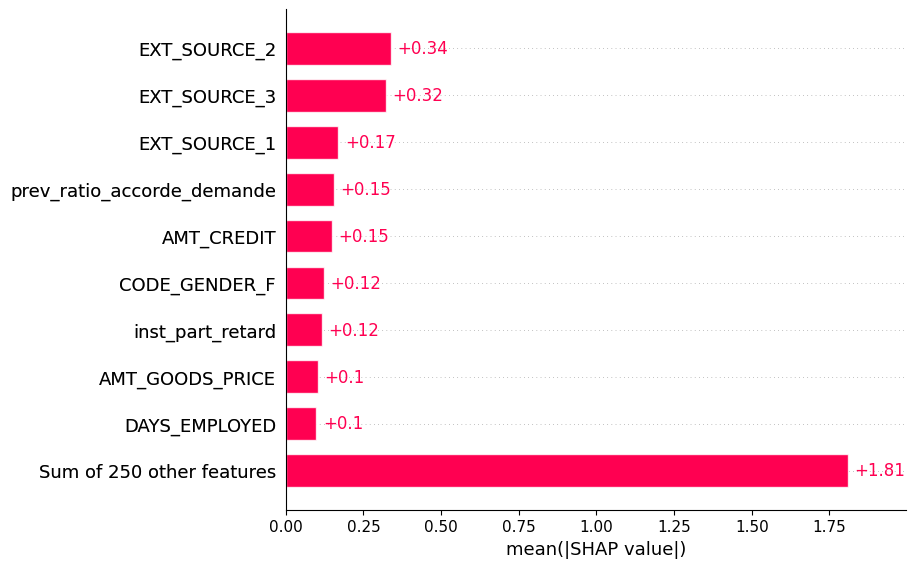

In [22]:
import shap

echantillon = X_val_final.sample(500, random_state=0)
shap_values = shap.TreeExplainer(model)(echantillon)

# selon la version de SHAP : 2 classes (3 dimensions) ou 1 seule ; on garde la classe « défaut »
vals = shap_values[:, :, 1] if shap_values.values.ndim == 3 else shap_values

shap.plots.bar(vals, max_display=10)